# Сравнение результатов пяти лабораторных работ

Сопоставляются KNN, логистическая и линейная регрессии, решающее дерево, случайный лес и градиентный бустинг. Для каждой работы рассматриваются два библиотечных варианта и две собственные реализации. Конфигурации выбраны на общих внутренних фолдах. Здесь используются метрики одинаковых отложенных выборок.

In [1]:
# Читаем результаты всех пяти работ и проверяем полноту комбинаций.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from labkit.experiments import VERSIONS

files = [Path("results") / f"lab_{index:02d}.csv" for index in range(1, 6)]
absent = [str(path) for path in files if not path.is_file()]
if absent:
    raise FileNotFoundError(f"Сначала выполните соответствующие лабораторные: {', '.join(absent)}")
scores = pd.concat([pd.read_csv(path) for path in files], ignore_index=True)
assert len(scores) == 50
assert scores.groupby(["lab", "task"]).version.apply(set).map(
    lambda present: present == {*VERSIONS, "dummy"}
).all()
assert not scores.duplicated(["lab", "task", "version"]).any()

## Основные метрики

Для Avila выше macro-F1 означает лучший баланс precision и recall по 12 классам. Для Tasmania ниже MAE означает меньший средний абсолютный промах мощности. Положительный прирост в обеих таблицах означает улучшение при переходе между указанными вариантами.

In [2]:
# Показываем основную метрику и оба прироста по каждой задаче.
specs = {
    "classification": ("Avila", "macro_f1", "Macro-F1", 1),
    "regression": ("Tasmania", "mae_mw", "MAE, МВт", -1),
}
pivots = {}
for task, (title, metric, label, direction) in specs.items():
    data = scores.loc[scores["task"] == task]
    pivot = data.pivot(index=["lab", "algorithm"], columns="version", values=metric)
    pivots[task] = pivot
    table = pivot.loc[:, ["dummy", *VERSIONS]].copy()
    table["прирост sklearn"] = direction * (table["sklearn tuned"] - table["sklearn baseline"])
    table["прирост свой"] = direction * (table["own tuned"] - table["own baseline"])
    display(Markdown(f"**{title} · {label}**"))
    display(table.round(5))

**Avila · Macro-F1**

,version,dummy,sklearn baseline,sklearn tuned,own baseline,own tuned,прирост sklearn,прирост свой
lab,algorithm,,,,,,,
1,KNN,0.04852,0.71828,0.88331,0.71828,0.88331,0.16502,0.16502
2,Логистическая / линейная регрессии,0.04852,0.39651,0.58688,0.39656,0.58776,0.19038,0.19120
3,Решающее дерево,0.04852,0.95820,0.98517,0.95867,0.97465,0.02697,0.01598
4,Случайный лес,0.04852,0.98152,0.98705,0.98058,0.98378,0.00553,0.00320
5,Градиентный бустинг,0.04852,0.78335,0.92901,0.78335,0.93160,0.14567,0.14826


**Tasmania · MAE, МВт**

,version,dummy,sklearn baseline,sklearn tuned,own baseline,own tuned,прирост sklearn,прирост свой
lab,algorithm,,,,,,,
1,KNN,0.08752,0.05975,0.05151,0.05975,0.05151,0.00824,0.00824
2,Логистическая / линейная регрессии,0.08752,0.08134,0.04799,0.08134,0.04799,0.03335,0.03335
3,Решающее дерево,0.08752,0.07690,0.06159,0.07740,0.06161,0.01531,0.01579
4,Случайный лес,0.08752,0.05184,0.04620,0.05239,0.04633,0.00564,0.00605
5,Градиентный бустинг,0.08752,0.07457,0.05014,0.07457,0.05014,0.02443,0.02443


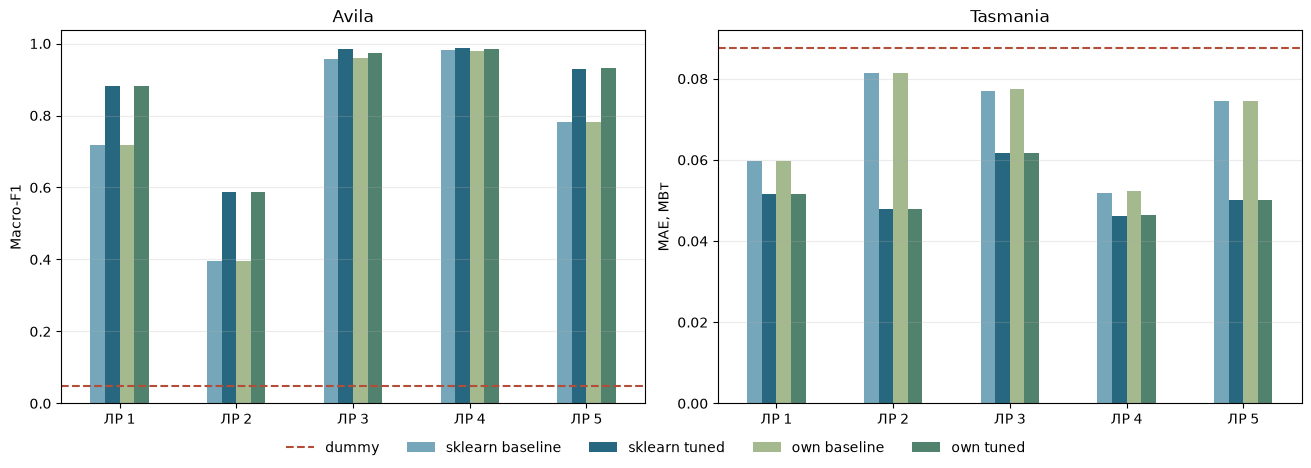

In [3]:
# Сравниваем все четыре варианта каждой модели с единым dummy для задачи.
palette = ["#76a6ba", "#286780", "#a4b98e", "#51826d"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
for ax, (task, (title, metric, label, direction)) in zip(axes, specs.items()):
    values = pivots[task]
    chart = values.loc[:, list(VERSIONS)].copy()
    chart.index = [f"ЛР {lab}" for lab, _ in chart.index]
    chart.plot.bar(ax=ax, color=palette, rot=0, legend=False)
    ax.axhline(values["dummy"].iloc[0], color="#b34d37", linestyle="--", label="dummy")
    ax.set(title=title, ylabel=label, xlabel="")
    ax.grid(axis="y", alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=5, frameon=False)
plt.show()

## Дополнительные метрики и выбор по валидации

Balanced accuracy и accuracy дают разные ракурсы на дисбаланс Avila. В регрессии пара MAE и RMSE показывает чувствительность к большим ошибкам, а R² сравнивает сумму квадратов ошибок с разбросом тестовых откликов. Столбец «Настройка» в таблицах показывает выбранную по CV гипотезу. Подробные параметры и результаты фолдов находятся в ноутбуках соответствующих ЛР.

In [4]:
# Выводим вторичные оценки и конфигурации улучшенных моделей.
for task, (title, metric, _, _) in specs.items():
    data = scores.loc[scores["task"] == task].dropna(axis=1, how="all")
    selected = data.loc[data["version"].isin(["sklearn tuned", "own tuned"])]
    display(Markdown(f"**{title}**"))
    display(selected.drop(columns=["task", "candidate"]).round(5))
    names = selected.loc[selected["version"] == "sklearn tuned", ["lab", "candidate"]]
    display(names.rename(columns={"candidate": "Настройка"}).set_index("lab"))

**Avila**

,lab,algorithm,version,macro_f1,balanced_accuracy,accuracy
2,1,KNN,sklearn tuned,0.88331,0.85999,0.86749
4,1,KNN,own tuned,0.88331,0.85999,0.86749
12,2,Логистическая / линейная регрессии,sklearn tuned,0.58688,0.72814,0.56721
14,2,Логистическая / линейная регрессии,own tuned,0.58776,0.73014,0.56760
22,3,Решающее дерево,sklearn tuned,0.98517,0.98362,0.98726
24,3,Решающее дерево,own tuned,0.97465,0.96681,0.98783
32,4,Случайный лес,sklearn tuned,0.98705,0.98325,0.98659
34,4,Случайный лес,own tuned,0.98378,0.97867,0.98256
42,5,Градиентный бустинг,sklearn tuned,0.92901,0.91141,0.88867
44,5,Градиентный бустинг,own tuned,0.93160,0.91448,0.89183


,Настройка
lab,
1,Робастное масштабирование
2,Квадратичные признаки и веса классов
3,Только веса классов
4,64 дерева
5,Глубина 4


**Tasmania**

,lab,algorithm,version,mae_mw,rmse_mw,r2
7,1,KNN,sklearn tuned,0.05151,0.06929,0.61922
9,1,KNN,own tuned,0.05151,0.06929,0.61922
17,2,Логистическая / линейная регрессии,sklearn tuned,0.04799,0.06213,0.69378
19,2,Логистическая / линейная регрессии,own tuned,0.04799,0.06213,0.69378
27,3,Решающее дерево,sklearn tuned,0.06159,0.08233,0.46229
29,3,Решающее дерево,own tuned,0.06161,0.08233,0.46230
37,4,Случайный лес,sklearn tuned,0.04620,0.06304,0.68479
39,4,Случайный лес,own tuned,0.04633,0.06338,0.68137
47,5,Градиентный бустинг,sklearn tuned,0.05014,0.06676,0.64647
49,5,Градиентный бустинг,own tuned,0.05014,0.06676,0.64647


,Настройка
lab,
1,"Геометрия, k=11 и взвешивание"
2,Квадратичные признаки координат и Ridge
3,Геометрия и ограничения дерева
4,Координаты и геометрия
5,"Координаты и геометрия, глубина 3"


## Выводы

In [5]:
# Сравниваем лидеров и число улучшений на общей отложенной выборке.
for task, (title, _, label, direction) in specs.items():
    values = pivots[task]
    lines = [f"**{title}**", ""]
    for prefix, description in [("sklearn", "sklearn"), ("own", "собственный код")]:
        baseline, tuned = f"{prefix} baseline", f"{prefix} tuned"
        primary = values[tuned] * direction
        lab, algorithm = primary.idxmax()
        holdout_score = values.loc[(lab, algorithm), tuned]
        gains = direction * (values[tuned] - values[baseline])
        improved = int((gains > 1e-8).sum())
        worsened = int((gains < -1e-8).sum())
        lines.append(
            f"- Лучший настроенный вариант ({description}) — ЛР {lab}, {algorithm} "
            f"({label} {holdout_score:.5f}). Качество повысилось в {improved} из 5 ЛР "
            f"и снизилось в {worsened} из 5."
        )
    best_baselines = values.loc[:, ["sklearn baseline", "own baseline"]]
    best = (best_baselines.stack() * direction).idxmax()
    lines.append(f"- Среди бейзлайнов лидирует ЛР {best[0]}, {best[1]} ({best[2]}).")
    display(Markdown("\n".join(lines)))

**Avila**

- Лучший настроенный вариант (sklearn) — ЛР 4, Случайный лес (Macro-F1 0.98705). Качество повысилось в 5 из 5 ЛР и снизилось в 0 из 5.
- Лучший настроенный вариант (собственный код) — ЛР 4, Случайный лес (Macro-F1 0.98378). Качество повысилось в 5 из 5 ЛР и снизилось в 0 из 5.
- Среди бейзлайнов лидирует ЛР 4, Случайный лес (sklearn baseline).

**Tasmania**

- Лучший настроенный вариант (sklearn) — ЛР 4, Случайный лес (MAE, МВт 0.04620). Качество повысилось в 5 из 5 ЛР и снизилось в 0 из 5.
- Лучший настроенный вариант (собственный код) — ЛР 4, Случайный лес (MAE, МВт 0.04633). Качество повысилось в 5 из 5 ЛР и снизилось в 0 из 5.
- Среди бейзлайнов лидирует ЛР 4, Случайный лес (sklearn baseline).

## Границы сравнения

Результаты Avila относятся к опубликованному разделению фрагментов одной рукописи. В редких классах малая поддержка, поэтому небольшое число ошибок заметно меняет macro-F1. Для Tasmania оценка относится к одному симулированному волновому сценарию и одной воспроизводимой подвыборке. Группировка по округлённой конфигурации исключает точное совпадение ключей между частями. Метрики отражают качество на этих выборках. Порядок моделей на новых рукописях и волновых сценариях требует отдельного эксперимента.